In [1]:
#import and config 
import os
import numpy as np
import pandas as pd
import tensorflow as tf

processed_path = "../dataset/processed"
models_path = "../Models"

interactions = pd.read_parquet(
    os.path.join(processed_path, "interactions.parquet")
)

retrieval_interactions = pd.read_parquet(
    os.path.join(processed_path, "retrieval_interactions.parquet")
)

recommendations_df = pd.read_parquet(
    os.path.join(processed_path, "faiss_recommendations.parquet")
)

print("Interactions:", interactions.shape)
print("Positive interactions:", retrieval_interactions.shape)
print("FAISS recommendations:", recommendations_df.shape)
print("TensorFlow:", tf.__version__)


Interactions: (1000209, 27)
Positive interactions: (575281, 3)
FAISS recommendations: (60380, 4)
TensorFlow: 2.21.0


In [2]:
#train-test split 
interactions_sorted = interactions.sort_values(
    ["user_id", "timestamp"]
).copy()

interactions_sorted["position"] = (
    interactions_sorted.groupby("user_id").cumcount()
)

interactions_sorted["user_count"] = (
    interactions_sorted.groupby("user_id")["user_id"].transform("size")
)

interactions_sorted["test_count"] = np.maximum(
    1,
    np.ceil(interactions_sorted["user_count"] * 0.2)
).astype(int)

ranking_train = interactions_sorted[
    interactions_sorted["position"] <
    interactions_sorted["user_count"] - interactions_sorted["test_count"]
].copy()

ranking_test = interactions_sorted[
    interactions_sorted["position"] >=
    interactions_sorted["user_count"] - interactions_sorted["test_count"]
].copy()

print("Ranking training data:", ranking_train.shape)
print("Ranking testing data:", ranking_test.shape)
print("Training users:", ranking_train["user_id"].nunique())
print("Testing users:", ranking_test["user_id"].nunique())

Ranking training data: (797758, 30)
Ranking testing data: (202451, 30)
Training users: 6040
Testing users: 6040


In [7]:
user_ids = sorted(retrieval_train["user_id"].astype(str).unique())
movie_ids = sorted(retrieval_train["movie_id"].astype(str).unique())

ranking_train["user_id"] = ranking_train["user_id"].astype(str)
ranking_train["movie_id"] = ranking_train["movie_id"].astype(str)

ranker_train_data = ranking_train[
    ranking_train["user_id"].isin(user_ids) &
    ranking_train["movie_id"].isin(movie_ids)
].copy()

ranker_train_data["label"] = (
    ranker_train_data["rating"] >= 4
).astype(np.float32)

print("Ranking training examples:", ranker_train_data.shape)
print("\nRating distribution:")
print(ranker_train_data["rating"].value_counts().sort_index())
print("\nLabel distribution:")
print(ranker_train_data["label"].value_counts().sort_index())

Ranking training examples: (757084, 28)

Rating distribution:
rating
1     38261
2     75023
3    190032
4    268384
5    185384
Name: count, dtype: int64

Label distribution:
label
0.0    303316
1.0    453768
Name: count, dtype: int64


In [4]:
#ranking split 
retrieval_sorted = retrieval_interactions.sort_values(
    ["user_id", "timestamp"]
).copy()

retrieval_sorted["position"] = retrieval_sorted.groupby("user_id").cumcount()
retrieval_sorted["user_count"] = retrieval_sorted.groupby("user_id")["user_id"].transform("size")

retrieval_sorted["test_count"] = np.where(
    retrieval_sorted["user_count"] >= 2,
    np.maximum(1, np.ceil(retrieval_sorted["user_count"] * 0.2)),
    0
)

retrieval_train = retrieval_sorted[
    retrieval_sorted["position"] <
    retrieval_sorted["user_count"] - retrieval_sorted["test_count"]
].copy()

retrieval_test = retrieval_sorted[
    retrieval_sorted["position"] >=
    retrieval_sorted["user_count"] - retrieval_sorted["test_count"]
].copy()

cutoffs = retrieval_test.groupby("user_id")["timestamp"].min()

user_cutoffs = interactions["user_id"].map(cutoffs)

ranking_train = interactions[
    user_cutoffs.isna() | (interactions["timestamp"] < user_cutoffs)
].copy()

ranking_test = interactions[
    user_cutoffs.notna() & (interactions["timestamp"] >= user_cutoffs)
].copy()

print("Ranking training data:", ranking_train.shape)
print("Ranking testing data:", ranking_test.shape)
print("Training users:", ranking_train["user_id"].nunique())
print("Testing users:", ranking_test["user_id"].nunique())

Ranking training data: (757990, 27)
Ranking testing data: (242219, 27)
Training users: 6040
Testing users: 6037


In [8]:
#loading the trained two tower model
class UserModel(tf.keras.Model):
    def __init__(self, user_ids):
        super().__init__()
        self.user_lookup = tf.keras.layers.StringLookup(
            vocabulary=user_ids, mask_token=None
        )
        self.user_embedding = tf.keras.layers.Embedding(
            len(user_ids) + 1, 64
        )

    def call(self, user_id):
        return self.user_embedding(self.user_lookup(user_id))


class MovieModel(tf.keras.Model):
    def __init__(self, movie_ids):
        super().__init__()
        self.movie_lookup = tf.keras.layers.StringLookup(
            vocabulary=movie_ids, mask_token=None
        )
        self.movie_embedding = tf.keras.layers.Embedding(
            len(movie_ids) + 1, 64
        )

    def call(self, movie_id):
        return self.movie_embedding(self.movie_lookup(movie_id))


user_model = UserModel(user_ids)
movie_model = MovieModel(movie_ids)

user_model(tf.constant(user_ids[:1]))
movie_model(tf.constant(movie_ids[:1]))

user_model.load_weights(
    os.path.join(models_path, "user_model.weights.h5")
)

movie_model.load_weights(
    os.path.join(models_path, "movie_model.weights.h5")
)

print("User model and movie model loaded successfully.")



User model and movie model loaded successfully.


In [9]:
#generating user and movie embedding 
user_embeddings = user_model(
    tf.constant(user_ids)
).numpy()

movie_embeddings = movie_model(
    tf.constant(movie_ids)
).numpy()

print("User embeddings:", user_embeddings.shape)
print("Movie embeddings:", movie_embeddings.shape)

User embeddings: (6038, 64)
Movie embeddings: (3456, 64)


In [10]:
#id-index mapping 
user_to_index = {
    user_id: index
    for index, user_id in enumerate(user_ids)
}

movie_to_index = {
    movie_id: index
    for index, movie_id in enumerate(movie_ids)
}

ranker_train_data["user_idx"] = (
    ranker_train_data["user_id"].map(user_to_index)
)

ranker_train_data["movie_idx"] = (
    ranker_train_data["movie_id"].map(movie_to_index)
)

print("Training data:", ranker_train_data.shape)
print("Missing user indices:", ranker_train_data["user_idx"].isna().sum())
print("Missing movie indices:", ranker_train_data["movie_idx"].isna().sum())

Training data: (757084, 30)
Missing user indices: 0
Missing movie indices: 0


In [11]:
#model input features 
user_indices = ranker_train_data["user_idx"].to_numpy(dtype=np.int32)
movie_indices = ranker_train_data["movie_idx"].to_numpy(dtype=np.int32)

X = np.concatenate(
    [
        user_embeddings[user_indices],
        movie_embeddings[movie_indices],
        np.sum(
            user_embeddings[user_indices] *
            movie_embeddings[movie_indices],
            axis=1,
            keepdims=True
        )
    ],
    axis=1
).astype(np.float32)

y = ranker_train_data["label"].to_numpy(dtype=np.float32)

print("Feature matrix:", X.shape)
print("Labels:", y.shape)
print("Feature data type:", X.dtype)

Feature matrix: (757084, 129)
Labels: (757084,)
Feature data type: float32


In [12]:
#splitting testing and validation data 
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training positive rate:", y_train.mean())
print("Validation positive rate:", y_val.mean())

Training features: (605667, 129)
Validation features: (151417, 129)
Training positive rate: 0.5993624
Validation positive rate: 0.5993647


In [13]:
#bulding Ranking MLP
ranking_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(129,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

ranking_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

ranking_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               16640     
                                                                 
 dropout (Dropout)           (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dropout_1 (Dropout)         (None, 64)                0         
                                                                 
 dense_2 (Dense)             (None, 1)                 65        
                                                                 
Total params: 24961 (97.50 KB)
Trainable params: 24961 (97.50 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [14]:
#traning ranking model 
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc",
    patience=3,
    mode="max",
    restore_best_weights=True
)

history = ranking_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=1024,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
592/592 [==============================] - 3s 4ms/step - loss: 0.5635 - accuracy: 0.7133 - auc: 0.7623 - val_loss: 0.5468 - val_accuracy: 0.7248 - val_auc: 0.7790
Epoch 2/10
592/592 [==============================] - 2s 4ms/step - loss: 0.5487 - accuracy: 0.7238 - auc: 0.7771 - val_loss: 0.5407 - val_accuracy: 0.7279 - val_auc: 0.7843
Epoch 3/10
592/592 [==============================] - 2s 4ms/step - loss: 0.5436 - accuracy: 0.7277 - auc: 0.7820 - val_loss: 0.5370 - val_accuracy: 0.7309 - val_auc: 0.7881
Epoch 4/10
592/592 [==============================] - 3s 5ms/step - loss: 0.5399 - accuracy: 0.7301 - auc: 0.7855 - val_loss: 0.5343 - val_accuracy: 0.7325 - val_auc: 0.7910
Epoch 5/10
592/592 [==============================] - 3s 5ms/step - loss: 0.5366 - accuracy: 0.7323 - auc: 0.7885 - val_loss: 0.5306 - val_accuracy: 0.7341 - val_auc: 0.7936
Epoch 6/10
592/592 [==============================] - 3s 5ms/step - loss: 0.5338 - accuracy: 0.7338 - auc: 0.7912 - val_loss: 0.52

In [16]:
#saving the ranking model 
ranking_model.save_weights(
    os.path.join(models_path, "ranking_model.weights.h5")
)

print("Ranking model weights saved successfully.")

Ranking model weights saved successfully.


In [17]:
print(recommendations_df.head())
print("\nUnique users:", recommendations_df["user_id"].nunique())
print("Unique movies:", recommendations_df["movie_id"].nunique())
print("Total candidates:", len(recommendations_df))

  user_id movie_id  retrieval_score  rank
0       1      914         1.195011     1
1       1     1947         1.042930     2
2       1     2080         1.023007     3
3       1      920         0.998976     4
4       1      595         0.987576     5

Unique users: 6038
Unique movies: 1246
Total candidates: 60380


In [18]:
#generating the candidate features
candidate_data = recommendations_df.copy()

candidate_data["user_id"] = candidate_data["user_id"].astype(str)
candidate_data["movie_id"] = candidate_data["movie_id"].astype(str)

candidate_data["user_idx"] = candidate_data["user_id"].map(user_to_index)
candidate_data["movie_idx"] = candidate_data["movie_id"].map(movie_to_index)

assert candidate_data[["user_idx", "movie_idx"]].notna().all().all()

candidate_user_idx = candidate_data["user_idx"].to_numpy(dtype=np.int32)
candidate_movie_idx = candidate_data["movie_idx"].to_numpy(dtype=np.int32)

X_candidates = np.concatenate(
    [
        user_embeddings[candidate_user_idx],
        movie_embeddings[candidate_movie_idx],
        np.sum(
            user_embeddings[candidate_user_idx] *
            movie_embeddings[candidate_movie_idx],
            axis=1,
            keepdims=True
        )
    ],
    axis=1
).astype(np.float32)

print("Candidate features:", X_candidates.shape)

Candidate features: (60380, 129)


In [19]:
#predicting the ranking score 
ranking_scores = ranking_model.predict(
    X_candidates,
    batch_size=1024,
    verbose=1
).flatten()

candidate_data["ranking_score"] = ranking_scores

print(candidate_data[
    ["user_id", "movie_id", "retrieval_score", "ranking_score"]
].head())

59/59 [==============================] - 0s 1ms/step
  user_id movie_id  retrieval_score  ranking_score
0       1      914         1.195011       0.867402
1       1     1947         1.042930       0.824755
2       1     2080         1.023007       0.718447
3       1      920         0.998976       0.849182
4       1      595         0.987576       0.781817


In [20]:
#generating the  personalized top 10 
ranked_recommendations = (
    candidate_data
    .sort_values(
        ["user_id", "ranking_score"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .head(10)
    .copy()
)

ranked_recommendations["rank"] = (
    ranked_recommendations
    .groupby("user_id")
    .cumcount() + 1
)

ranked_recommendations = ranked_recommendations[
    ["user_id", "movie_id", "ranking_score", "rank"]
].reset_index(drop=True)

print("Final recommendations:", ranked_recommendations.shape)
print("\nUser 1 recommendations:")
print(ranked_recommendations[
    ranked_recommendations["user_id"] == "1"
])

Final recommendations: (60380, 4)

User 1 recommendations:
  user_id movie_id  ranking_score  rank
0       1      953       0.873897     1
1       1      914       0.867402     2
2       1      920       0.849182     3
3       1      899       0.840350     4
4       1     1947       0.824755     5
5       1       17       0.806320     6
6       1      595       0.781817     7
7       1     2565       0.747197     8
8       1     2080       0.718447     9
9       1     2081       0.702712    10


In [21]:
ranked_recommendations.to_parquet(
    os.path.join(processed_path, "ranked_recommendations.parquet"),
    index=False
)

print("Ranked recommendations saved successfully.")
print("Total recommendations:", len(ranked_recommendations))
print("Unique users:", ranked_recommendations["user_id"].nunique())

Ranked recommendations saved successfully.
Total recommendations: 60380
Unique users: 6038


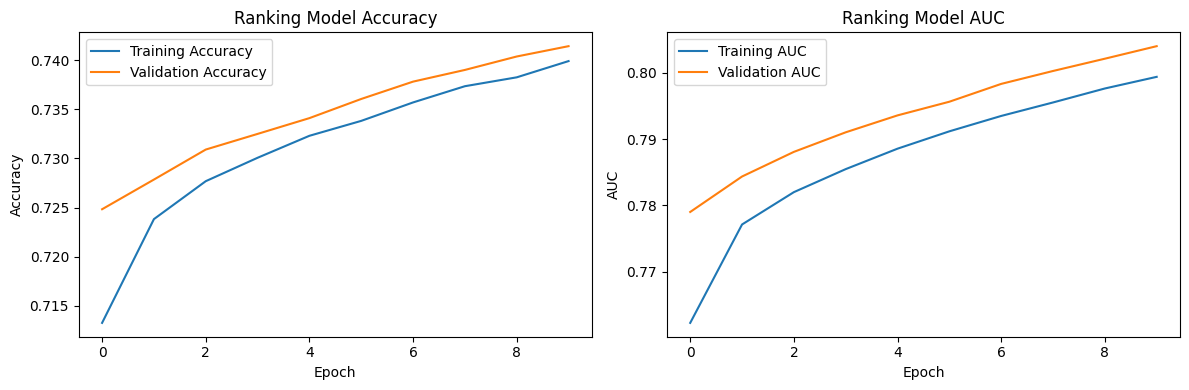

In [25]:
#Accuracy and AUC
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Ranking Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["auc"], label="Training AUC")
plt.plot(history.history["val_auc"], label="Validation AUC")
plt.title("Ranking Model AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.legend()

plt.tight_layout()
plt.show()

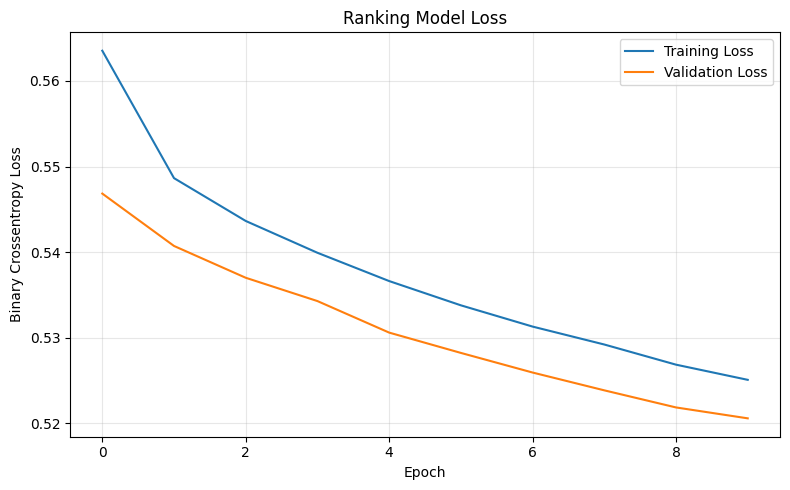

In [24]:
#trainging and validation loss 
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Ranking Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

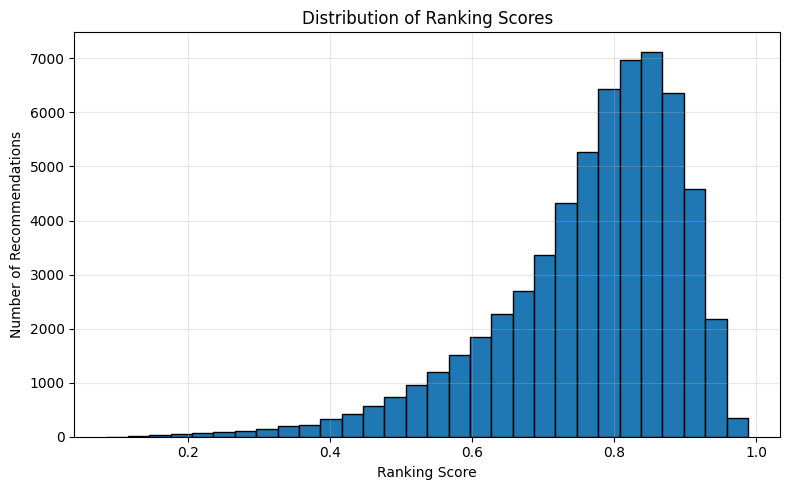

In [26]:
#Ranking score distribution
plt.figure(figsize=(8, 5))

plt.hist(
    ranked_recommendations["ranking_score"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Ranking Scores")
plt.xlabel("Ranking Score")
plt.ylabel("Number of Recommendations")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()